# Lesson 1.1: R basics and Calculating Screening Values 

In this lesson, we will use R to calculate screening values of methylmercury in fish, or the boundary of the highest average amount of mercury in fish that would not exceed the reference dose at a given consumption rate.

Lesson 1.1 Goals: 

- Learn what a package is, install and load `tidyverse`
- Learn about different data structures and create objects, vectors, and a data frame in R
- Calculate the screening value of mercury in fish for different consumption rates
- Create plot of screening values and discuss how data visualization can help interpret data and understand a problem 

## Definitions

There are a few new terms that come with learning to program for ths first time. 

*Package*: free libraries of code that expand what you can do in R. Packages can contain code, data, and documentation. 

*Function*: a function is a reusable block of code that allows you to automate specific tasks. Functions take inputs inside of parentheses. One of the first examples shown below is the library() function, which takes the name of a package as input

*Object*: a fundamental data structure in R, which can contain different types of data such as a number, a word (we call them characters), lists, or data frames

Read more about R terminology [here](https://librarycarpentry.github.io/lc-r/reference.html).

## Loading packages

"Packages" are computer code that someone wrote to do a particular thing. By loading a package, R downloads that code, so that you can do that thing yourself. Think of packages as tools for you to use in R that aren't automatically part of R when you first installed it. The package below allows you to do  more things in R, and makes coding much easier! 

Below, we install the package [tidyverse](https://www.tidyverse.org/) which we'll use to organize data and to make pretty graphs. You only need to install a package once, but every time you use R you will have to load from the library using `library()`.

*Note:* these lessons are organized with combinations of text and code chunks. Within the code chunks below you will find comments that begin with `#` - this is text that the computer will ignore, and is used to document the steps being taken in the code. 

In [ ]:
# Load packages 
# this code checks to see if the package is already installed, and if not, it installs it. 
if(!require("tidyverse")) install.packages("tidyverse")
# loads package into R so you can use it
library(tidyverse)

Loading required package: tidyverse

── Attaching core tidyverse packages ─────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## Creating objects in R 

We will work with different types of objects and data types, including numbers, characters, vectors, and data frames. Here we start with creating objects for the variables and parameters used to calculate the screening value, or safe limit, of fish consumption. According to the [FDA](https://www.fda.gov/food/environmental-contaminants-food/technical-information-development-fdaepa-advice-about-eating-fish-those-who-might-become-or-are), the screening value, or amount of safe fish consumption, depends on a person's body weight and how often they consume the fish. 

First, the variables `weight` and `days_per_week` are set. 

We can view what an object is by running the `print()` function on it. 

In [ ]:
# Define variables
weight = 120 # lbs
days_per_week = 1 # days per week eating fish 

# print the values 
print(weight)
print(days_per_week)

[1] 120
[1] 1


Once we create an object, we can use math or functions on it. Below we calculate `cr`, the mean daily consumption rate of the species of interest (g/d), based on the `days_per_week`

Doing math in R requires that you use the correct symbols for the operations. For example, `*` is multiplication, `/` is division, and `^` is exponentiation.

In the example below, the consumption rate is calculated as the serving size (110g) multiplied by the number of days per week, divided by 7, to end up with the consumption rate per week. 

In [3]:
# use days per week to calculate mean daily consumption rate 
cr = 110*days_per_week/7 
print(cr)

[1] 15.71429


## Calculating screening values for mercury in fish

Below we use the `weight`, mean daily consumption rate `cr`, and the reference dose `RfD` to calculate the screening value, based on FDA recommendations. Because the equation requires body weight in kg, we multiply our body weight in lbs by 0.45. 

$SV = RfD*weight*0.45/CR$

In [ ]:
# Create new object for the reference dose
RfD = 0.1 # ug mercury /kg body weight/day

# Calculate screening value  
screening_value = RfD * weight * 0.45 / cr

print(screening_value)

[1] 0.3436364


💻 Try changing the value for `weight` or `days_per_week`, and rerunning the two code chunks above to see the new safe screening value. 

### Creating vectors 

Next we will create a vector, which is list of the same type of object, that can similarly be used in a function or equation. Below we have two vectors, `weight` and `servings`. 


In [ ]:
# Create vectors 
weight = c(140, 175, 200)
servings = c(1, 6, 3)

# can print entire vector 
print(weight)
print(servings)

# or a single value from a vector 
weight[1]

[1] 140 175 200
[1] 1 6 3


[1] 140

### Creating a data frame from vectors 

Multiple vectors of the same length become columns in a data frame. Below we make a data frame named `sv_df`. When we preview it using the `head()` function, we can see it is comprised of two columns, with the same name as the vectors we created. 

Inside a data frame, columns are referred to using `$`. We can also preview a single row, using brackets. 

We then add a third column, where we apply the equation for the screening value to each row 

In [ ]:
# create data frame with two columns - from the vectors weight, servings 
sv_df <- data.frame(weight, servings)

head(sv_df) # preview the entire data frame 

head(sv_df$weight) # see the column weight 

# Add column for screening value
sv_df$screen_val = RfD * sv_df$weight * 0.45 / (110 * sv_df$serving / 7)

head(sv_df)

,weight,servings
,<dbl>,<dbl>
1,140,1
2,175,6
3,200,3


[1] 140 175 200

,weight,servings,screen_val
,<dbl>,<dbl>,<dbl>
1,140,1,0.40090909
2,175,6,0.08352273
3,200,3,0.19090909


## Visualizing Screening Value vs. Servings Per Week with ggplot

Above, we used `head()` to preview our data frame. For longer data frames this will print out the first 6 rows. 

Another way to preview and explore data frames is to visualize it. Throughout this module, we will use [ggplot2](https://ggplot2.tidyverse.org/). This package was loaded with `tidyverse`. 

There are a few key terms to know when plotting with `ggplot2`:

* `ggplot()`: the function that creates the plot. It requires two inputs:

  1. the data frame you want to plot, labelled as `data`
  2. the aesthetics of the plot, labelled as `mapping=aes()`. This is where you specify what variables you want to plot on the x and y axes.

* `geom`: short for geometric element, this represents how you want to plot your data, such as points, lines, or polygons. You can add multiple geoms to the same plot. 

We will create a plot step by step, starting with running `ggplot()` with our dataframe as the input. We then add layers to it using a plus sign. 

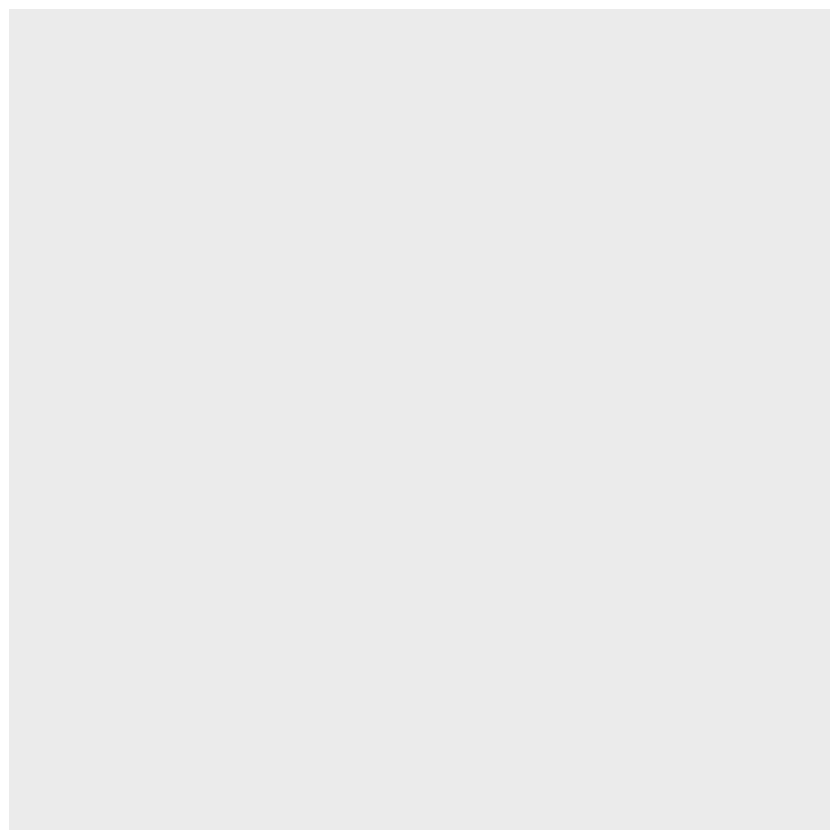

In [ ]:
ggplot(data=sv_df)


Starting with `ggplot()` created the plot, but we need to also include the variables we want to plot. We do this using `aes()` and then include the column name you want on the x-axis, and the column name for the y-axis. 


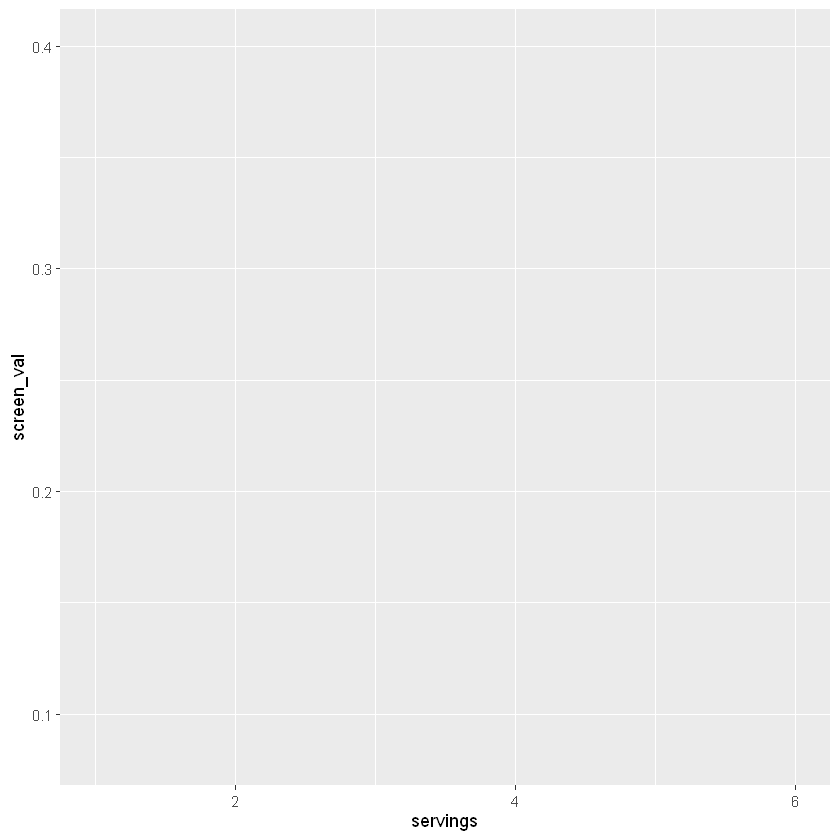

In [ ]:
 ggplot(data=sv_df, 
        aes(x=servings, y=screen_val))


Next we need to assign a `geom` - this could be a scatter plot, line plot, or boxplot. We will start with plotting as points, using `geom_point()`. 


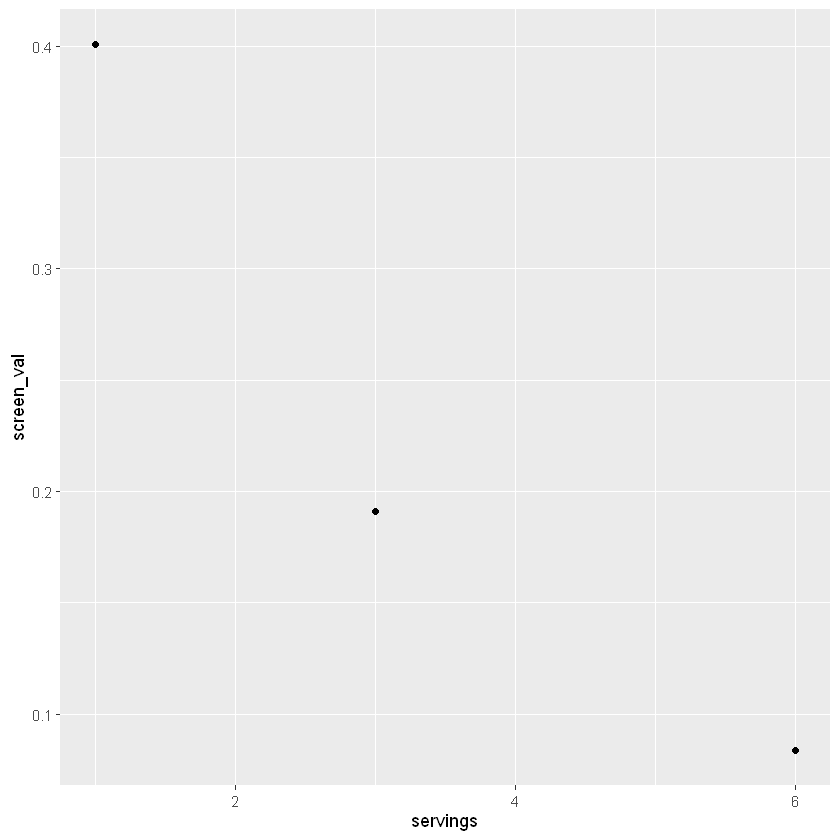

In [ ]:
 ggplot(data=sv_df, 
        aes(x=servings, y=screen_val)) +
    geom_point()


Now we have a draft of our first plot! We can continue to add layers and change the settings to have the plot tell us more about our data, or to make it look nicer. 

Variables can be included as colors - in this example we set the weight to `fill` which will fill in the column with a color gradient for our weight values. 


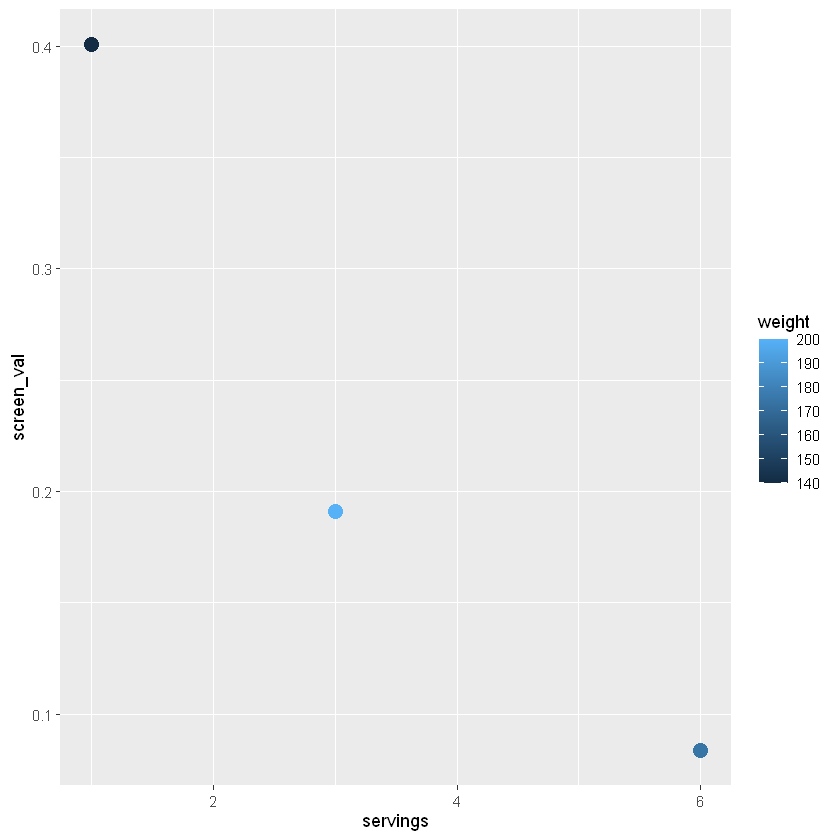

In [ ]:
 ggplot(data=sv_df, 
        aes(x=servings, y=screen_val, col=weight)) + 
    geom_point(size=4)


We can also change the `theme`, which alters the background and style of our plot. 


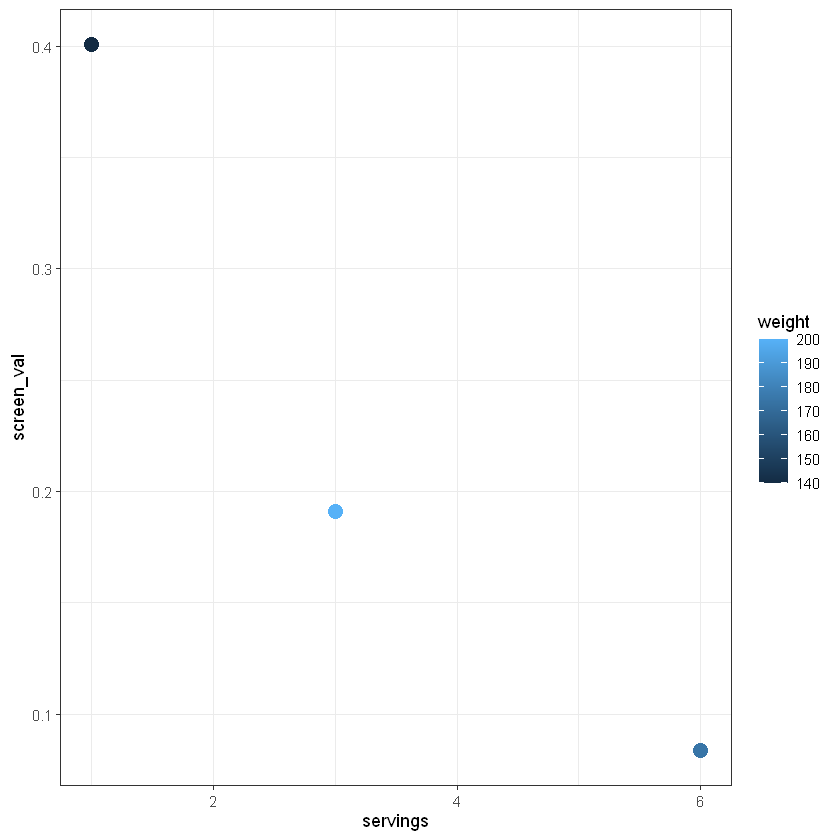

In [ ]:
 ggplot(data=sv_df, 
        aes(x=servings, y=screen_val, col=weight)) + 
    geom_point(size=4) +
    theme_bw() 


Finally we can add a title and change the labels to be more descriptive using `labs()`. 

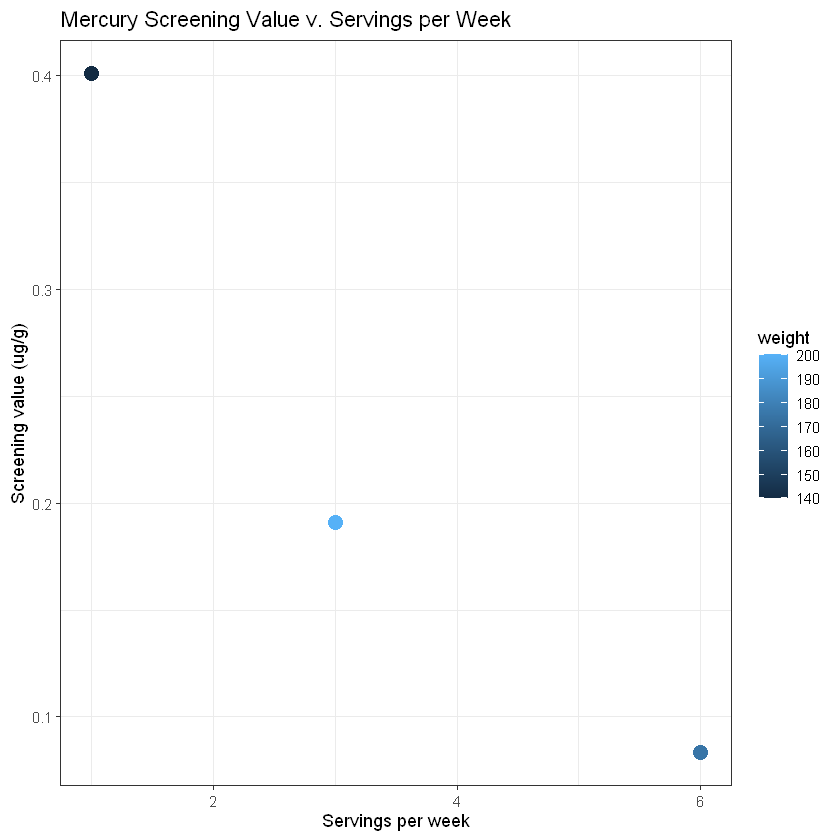

In [ ]:
 ggplot(data=sv_df, 
        aes(x=servings, y=screen_val, col=weight)) + 
    geom_point(size=4) +
    theme_bw() +
    labs(x="Servings per week", y="Screening value (ug/g)", title="Mercury Screening Value v. Servings per Week")

You should start to see a relationship between servings per week and screening value, but there are only 3 data points included above. Run the following code to create a similar plot with more data and get a better idea of the relationship between weight, servings per week, and screening value. 

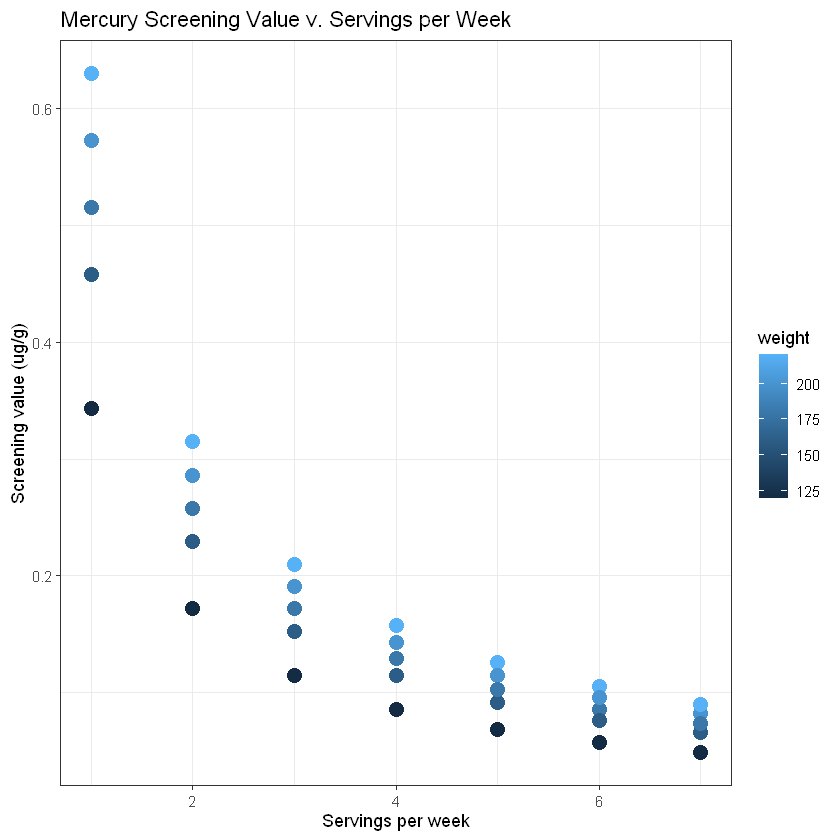

In [ ]:
weight = rep(c(120, 160, 180, 200, 220), 7)
serving = rep(seq(1:7), 5)
sv_df_long = data.frame(weight, serving)
sv_df_long$screen_val = RfD*sv_df_long$weight*0.45/(110*sv_df_long$serving/7)

ggplot(sv_df_long) + 
    geom_point(aes(x=serving, y=screen_val, col=weight), size=4) + 
    theme_bw() +
    labs(x="Servings per week", y="Screening value (ug/g)", title="Mercury Screening Value v. Servings per Week")

🧠✍️ **Class Questions** 

*  How would you describe this graph and the relationship between screening value, consumption rate, and weight? What happens to the distribution in screening values as the number of servings per week increase?
*   With this information in mind, consider how to make decisions with the data on mercury content in fish -- how should we consider the screening value for different ages? For example, what screening value would be safer for children, who weigh less than the average adult? 

## Lesson 1.1 Recap

In Lesson 1.1 we learned how to:
- define and `print()` an object in R 
- use R for equations
- create a vector and a data frame
- visualize data with `ggplot()`
- describe the relationsihp between weight, servings of fish, and screening values of mercury 

We will build on this in the following lessons. 